In [1]:
print("E-commerce Sales Analysis")
print("My first Python project is ready!")

E-commerce Sales Analysis
My first Python project is ready!


In [2]:
import pandas as pd

df = pd.read_csv("ecommerce_sales.csv")

df.head()

,Order ID,Order Date,Product,Category,Quantity,Unit Price,Customer City
0,1001,2026-01-05,Laptop,Electronics,1,55000,Delhi
1,1002,2026-01-08,Headphones,Electronics,2,1500,Mumbai
2,1003,2026-01-12,T-Shirt,Clothing,3,500,Jaipur
3,1004,2026-02-03,Smartphone,Electronics,1,25000,Delhi
4,1005,2026-02-10,Shoes,Footwear,2,2000,Mumbai


In [3]:
print("Dataset rows and columns:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset rows and columns:
(10, 7)

Column names:
['Order ID', 'Order Date', 'Product', 'Category', 'Quantity', 'Unit Price', 'Customer City']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Order ID       10 non-null     int64
 1   Order Date     10 non-null     str  
 2   Product        10 non-null     str  
 3   Category       10 non-null     str  
 4   Quantity       10 non-null     int64
 5   Unit Price     10 non-null     int64
 6   Customer City  10 non-null     str  
dtypes: int64(3), str(4)
memory usage: 1014.0 bytes


In [4]:
# Check missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

# Check dataset size
print("\nDataset shape:")
print(df.shape)

Missing values:
Order ID         0
Order Date       0
Product          0
Category         0
Quantity         0
Unit Price       0
Customer City    0
dtype: int64

Duplicate rows:
0

Dataset shape:
(10, 7)


In [5]:
# Calculate sales for each order
df["Sales"] = df["Quantity"] * df["Unit Price"]

# Display the updated dataset
df.head()

,Order ID,Order Date,Product,Category,Quantity,Unit Price,Customer City,Sales
0,1001,2026-01-05,Laptop,Electronics,1,55000,Delhi,55000
1,1002,2026-01-08,Headphones,Electronics,2,1500,Mumbai,3000
2,1003,2026-01-12,T-Shirt,Clothing,3,500,Jaipur,1500
3,1004,2026-02-03,Smartphone,Electronics,1,25000,Delhi,25000
4,1005,2026-02-10,Shoes,Footwear,2,2000,Mumbai,4000


In [6]:
total_sales = df["Sales"].sum()

print("Total E-commerce Sales:", total_sales)

Total E-commerce Sales: 98800


In [7]:
# Calculate total sales for each product
product_sales = df.groupby("Product")["Sales"].sum()

# Sort products from highest to lowest sales
product_sales = product_sales.sort_values(ascending=False)

# Display the results
print(product_sales)

Product
Laptop        55000
Smartphone    25000
Shoes          4000
Headphones     3000
Watch          3000
T-Shirt        2500
Keyboard       2400
Mouse          2100
Jeans          1800
Name: Sales, dtype: int64


In [8]:
top_products = product_sales.head(5)

print("Top 5 Products by Sales:")
print(top_products)

Top 5 Products by Sales:
Product
Laptop        55000
Smartphone    25000
Shoes          4000
Headphones     3000
Watch          3000
Name: Sales, dtype: int64


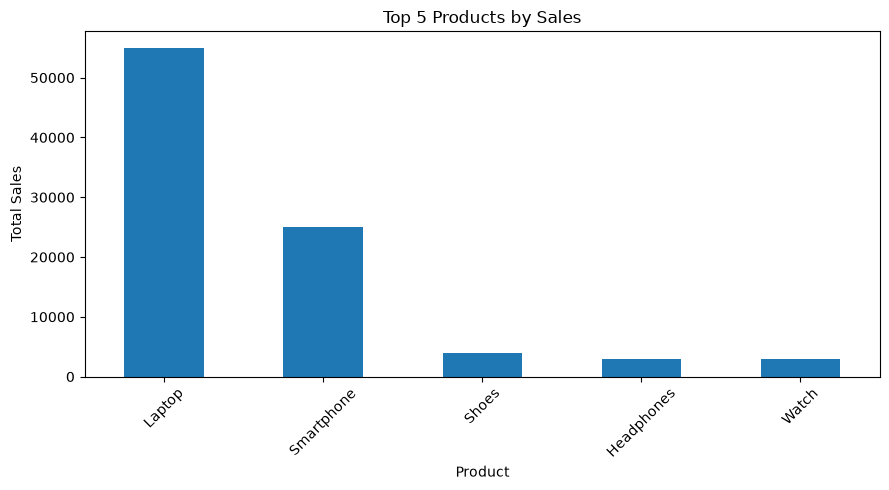

In [9]:
import matplotlib.pyplot as plt

top_products.plot(kind="bar", figsize=(9, 5))

plt.title("Top 5 Products by Sales")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
# Calculate total sales for each category
category_sales = df.groupby("Category")["Sales"].sum()

# Sort categories by sales
category_sales = category_sales.sort_values(ascending=False)

print("Category-wise Sales:")
print(category_sales)

Category-wise Sales:
Category
Electronics    87500
Clothing        4300
Footwear        4000
Accessories     3000
Name: Sales, dtype: int64


In [11]:
# Convert Order Date into datetime format
df["Order Date"] = pd.to_datetime(df["Order Date"])

# Extract month from each order date
df["Month"] = df["Order Date"].dt.to_period("M")

# Calculate monthly sales
monthly_sales = df.groupby("Month")["Sales"].sum()

print("Monthly Sales:")
print(monthly_sales)

Monthly Sales:
Month
2026-01    59500
2026-02    30800
2026-03     8500
Freq: M, Name: Sales, dtype: int64


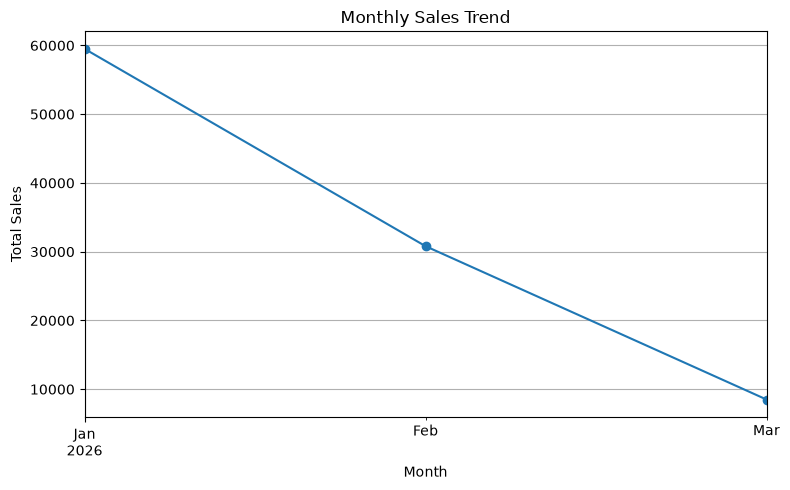

In [12]:
monthly_sales.plot(kind="line", marker="o", figsize=(8, 5))

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
# Find the best-selling product
best_product = product_sales.idxmax()
best_product_sales = product_sales.max()

# Find the highest-selling category
best_category = category_sales.idxmax()
best_category_sales = category_sales.max()

# Find the month with the highest sales
best_month = monthly_sales.idxmax()
best_month_sales = monthly_sales.max()

print("BUSINESS INSIGHTS")
print("-----------------")
print(f"Top product by sales: {best_product}")
print(f"Sales from this product: {best_product_sales}")
print(f"Top category: {best_category}")
print(f"Sales from this category: {best_category_sales}")
print(f"Best month: {best_month}")
print(f"Sales in the best month: {best_month_sales}")

BUSINESS INSIGHTS
-----------------
Top product by sales: Laptop
Sales from this product: 55000
Top category: Electronics
Sales from this category: 87500
Best month: 2026-01
Sales in the best month: 59500
